# First symplectic corrected product formula

Planned, unexecuted prototype for disjoint ZZ/X pairs. The source, equations and finite run contract must be reviewed before execution. This notebook has no saved validation output.


In [1]:
from pathlib import Path
import sys, inspect, importlib.metadata
roots = (Path.cwd(), *Path.cwd().parents)
ROOT = next(path for path in roots if (path / "src/openquantum/simulation/corrected_product_formula.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
from openquantum.simulation import corrected_product_formula as cpf
assert sys.version_info[:3] == (3, 12, 14)
assert importlib.metadata.version("qiskit") == "2.6.2"
assert Path(inspect.getfile(cpf)).resolve() == (ROOT / "src/openquantum/simulation/corrected_product_formula.py").resolve()


The declared known input uses H on both wires and S on the lower wire. Every complete trial includes resets, both corrector boundaries, all Strang steps and both readout bits.


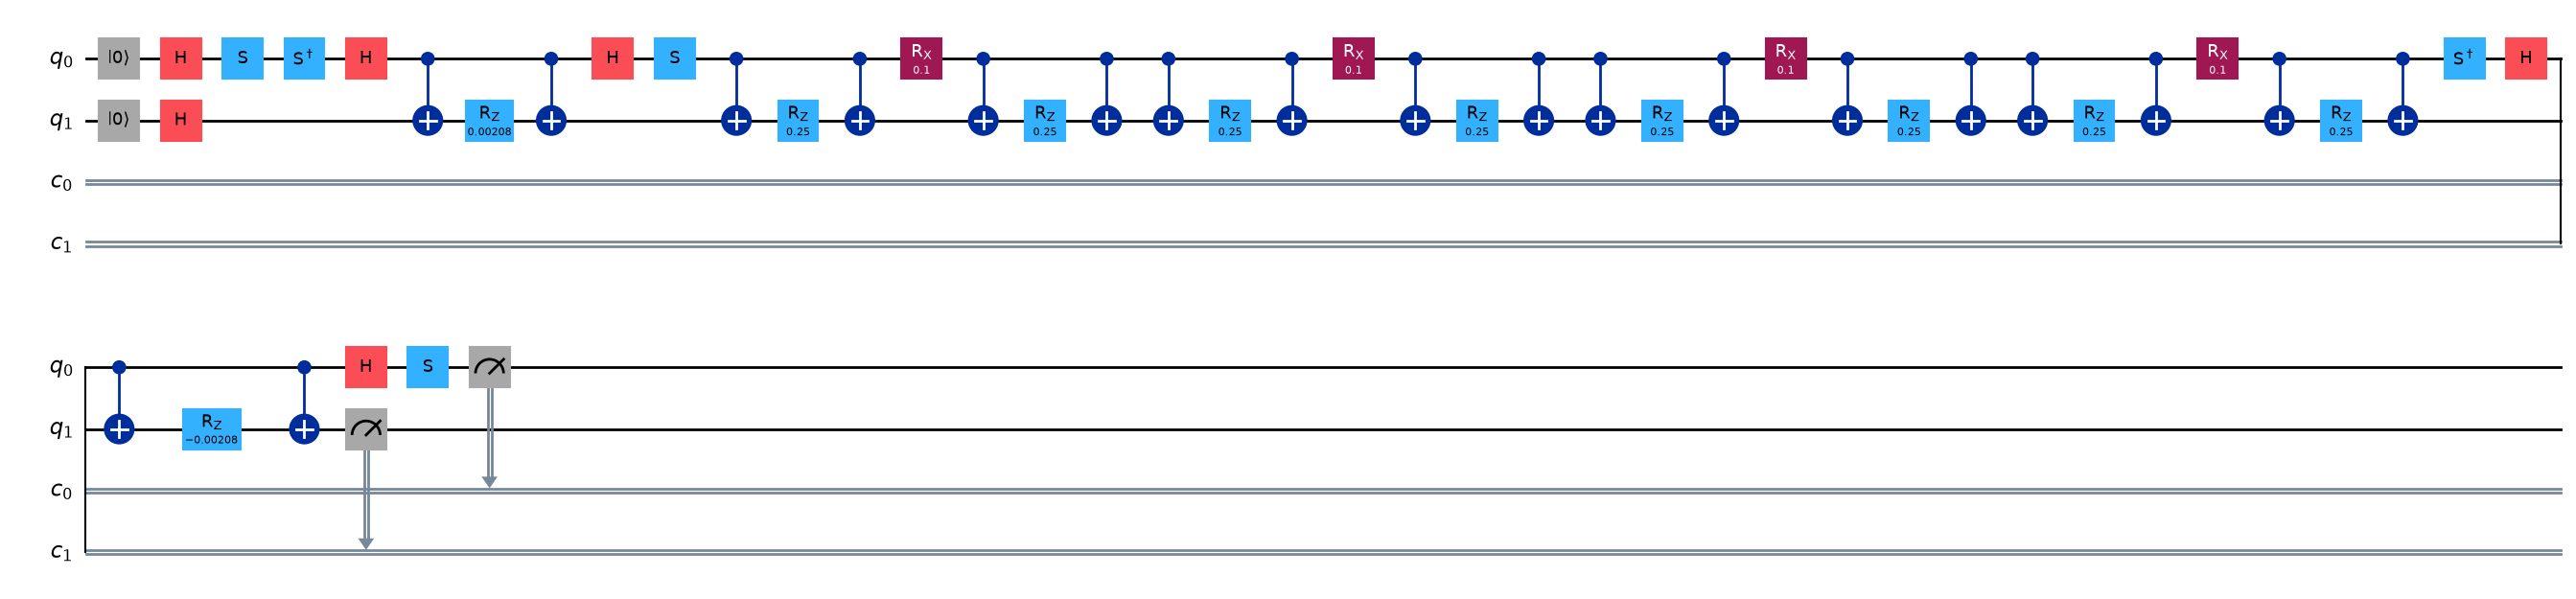

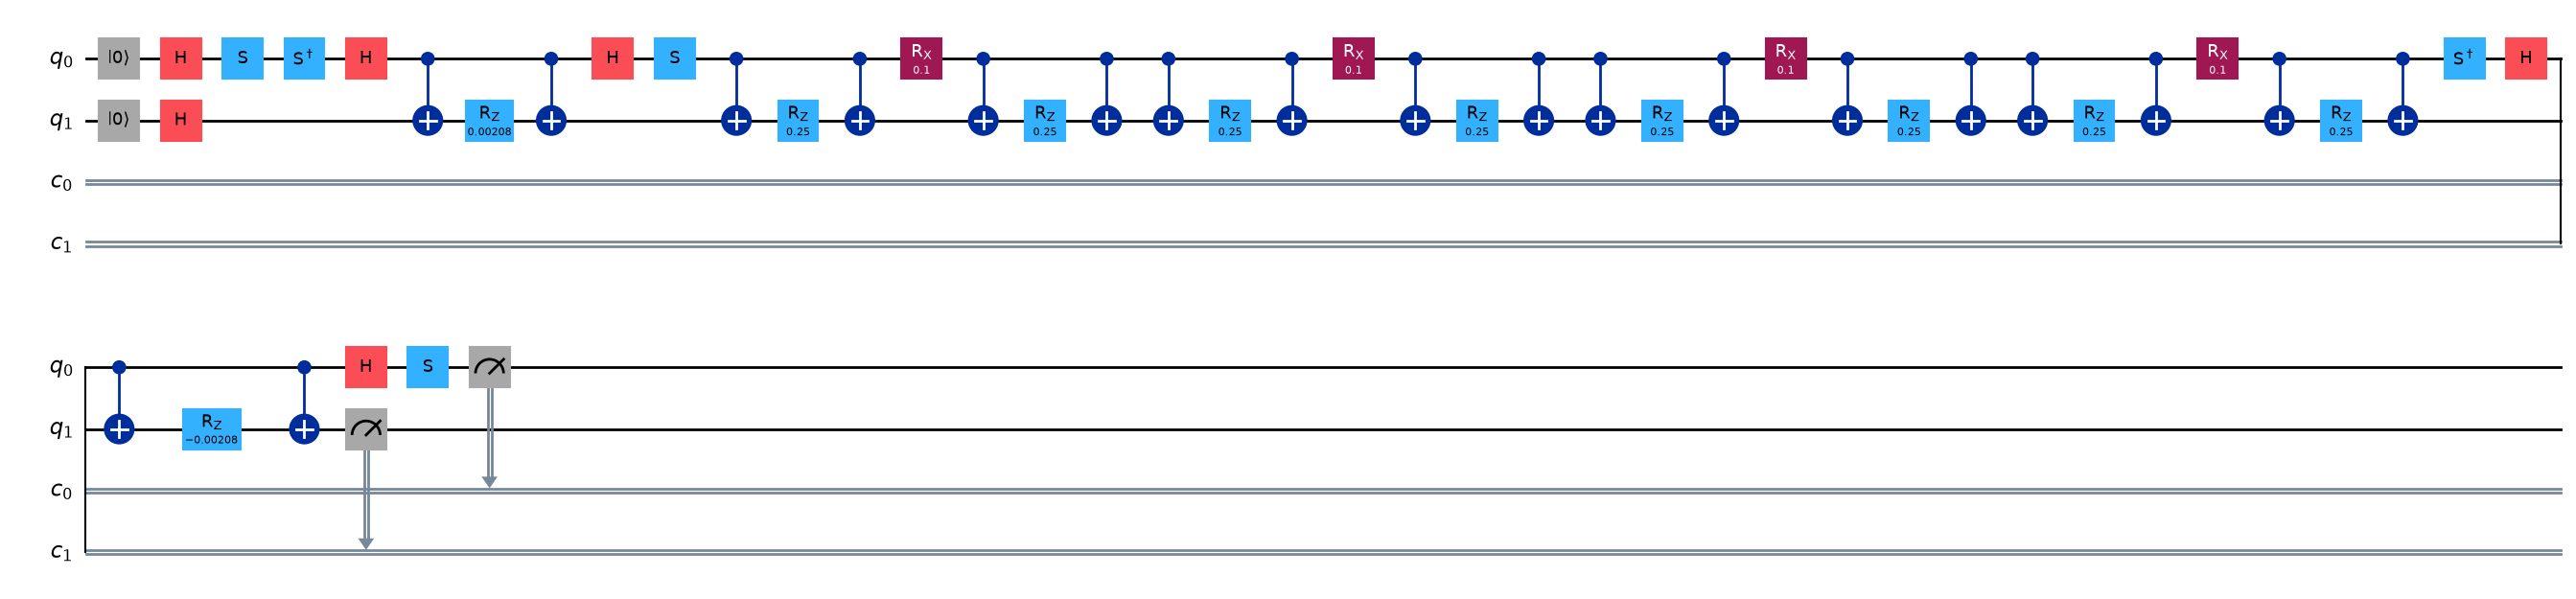

In [2]:
model = cpf.PairModel(1, alpha="1/5")
circuit = cpf.complete_trial(model, "1", 4)
circuit.draw("mpl", fold=40, cregbundle=False)


The independent closed-form pair answer and the bit-basis matrix exponential are distinct classical references. Output below would come from genuine execution, not a saved-result placeholder.


In [3]:
result = cpf.compare_case(model, "1", 4)
result


{'model': {'pairs': 1,
  'qubits': 2,
  'a_exact': ['1'],
  'b_exact': ['1'],
  'alpha_exact': '1/5',
  'A_norm_exact': '1',
  'B0_norm_exact': '1',
  'perturbation_norm_ratio_exact': '1/5',
  'Hamiltonian': 'sum_j a_j Z_(2j)Z_(2j+1) + alpha*b_j X_(2j)',
  'SDK_pair_label': 'ZY means Y on first q[2j], Z on partner q[2j+1]',
  'scope': 'Noninteracting disjoint pairs; classically factorized toy, not an application advantage.'},
 'time_exact': '1',
 'repetitions': 4,
 'independent_expm_max_entry_discrepancy': 1.5700924586837752e-16,
 'methods': {'strang': {'operator_formula_max_entry_discrepancy': 1.5700924586837752e-16,
   'operator_exact_dynamics_error': 0.0019011650531075715,
   'state_preparation_max_entry_discrepancy': 2.355138688025663e-16,
   'reset_density_max_entry_discrepancy': 2.2247786310271853e-16,
   'state_vector_error': 0.0019011650531073796,
   'state_infidelity': 3.6144252943959287e-06,
   'Z0_mean': 0.17693561778924988,
   'Z0_bias': 0.001979251961223061,
   'probabilit

In [4]:
signed = cpf.PairModel(2, a=("1", "1/2"), b=("1", "-3/4"), alpha="1/5")
cpf.compare_case(signed, "1", 2)


{'model': {'pairs': 2,
  'qubits': 4,
  'a_exact': ['1', '1/2'],
  'b_exact': ['1', '-3/4'],
  'alpha_exact': '1/5',
  'A_norm_exact': '3/2',
  'B0_norm_exact': '7/4',
  'perturbation_norm_ratio_exact': '7/30',
  'Hamiltonian': 'sum_j a_j Z_(2j)Z_(2j+1) + alpha*b_j X_(2j)',
  'SDK_pair_label': 'ZY means Y on first q[2j], Z on partner q[2j+1]',
  'scope': 'Noninteracting disjoint pairs; classically factorized toy, not an application advantage.'},
 'time_exact': '1',
 'repetitions': 2,
 'independent_expm_max_entry_discrepancy': 2.3479724158959924e-16,
 'methods': {'strang': {'operator_formula_max_entry_discrepancy': 7.947987303456223e-16,
   'operator_exact_dynamics_error': 0.00952333422612051,
   'state_preparation_max_entry_discrepancy': 1.2412670766236366e-16,
   'reset_density_max_entry_discrepancy': 8.333897564733124e-17,
   'state_vector_error': 0.007962486922896365,
   'state_infidelity': 6.340019307071731e-05,
   'Z0_mean': 0.18304893693572377,
   'Z0_bias': 0.008092571107696733,

The following source-only larger circuits are counted without dense simulation. They do not establish fixed-accuracy scaling or physical costs.


In [5]:
rows = []
for pairs in (1, 4, 16, 32):
    ledger = cpf.logical_ledger(cpf.PairModel(pairs, alpha="1/5"), "1", 8)
    rows.append({"pairs": pairs, "qubits": 2*pairs, "source_operations": ledger["source_operations"], "continuous_rotations": ledger["continuous_rotation_calls"], "simulation_performed": False})
rows


[{'pairs': 1,
  'qubits': 2,
  'source_operations': 77,
  'continuous_rotations': 26,
  'simulation_performed': False},
 {'pairs': 4,
  'qubits': 8,
  'source_operations': 308,
  'continuous_rotations': 104,
  'simulation_performed': False},
 {'pairs': 16,
  'qubits': 32,
  'source_operations': 1232,
  'continuous_rotations': 416,
  'simulation_performed': False},
 {'pairs': 32,
  'qubits': 64,
  'source_operations': 2464,
  'continuous_rotations': 832,
  'simulation_performed': False}]